# Tasks for laboratory assignment 3

In [1]:
# imports section

import os
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, cross_val_score, KFold, StratifiedKFold
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error, accuracy_score, f1_score,
                             roc_auc_score, roc_curve, classification_report, ConfusionMatrixDisplay)
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.optimize import curve_fit

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 20)
RANDOM_STATE = 42

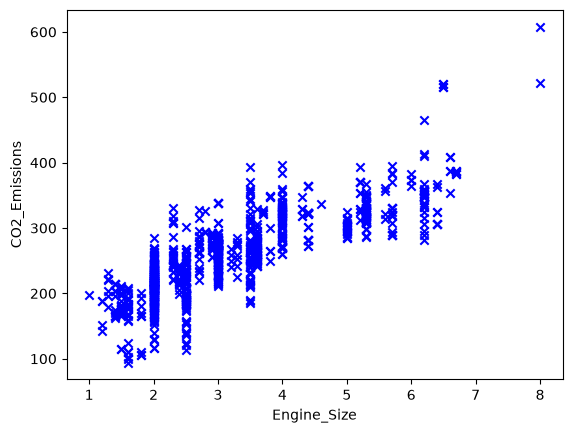

In [2]:
def build_plot(file_path, x, y):
    data = pd.read_csv(file_path)
    plt.scatter(data[x], data[y], c='blue', marker='x')
    plt.xlabel(x)
    plt.ylabel(y)
    return plt

build_plot('resources/CO2_emission.csv', 'Engine_Size', 'CO2_Emissions').show()

In [3]:
def extract_texts_from_file(file_path):
    """
    Extract the text data from the csv file

    Args:
        file_path (str): Relative location of the csv file in the project.

    Returns:
        pd.DataFrame: The loaded table (rows can be sliced like a list, e.g. data[:50]).
    """
    if not file_path or not os.path.exists(file_path):
        print(f'File not found: {file_path!r}')
        return pd.DataFrame()
    try:
        data = pd.read_csv(file_path, encoding='utf-8')
    except UnicodeDecodeError:
        data = pd.read_csv(file_path, encoding='latin-1')
    # drop index columns saved by pandas (e.g. 'Unnamed: 0') and trim column names
    data = data.loc[:, ~data.columns.astype(str).str.startswith('Unnamed')]
    data.columns = [str(column).strip() for column in data.columns]
    return data

data = extract_texts_from_file('resources/heart.csv')
print(data[:50])

    age  sex  cp  trtbps  chol  fbs  restecg  thalachh  exng  oldpeak  slp  caa  thall  output
0    63    1   3     145   233    1        0       150     0      2.3    0    0      1       1
1    37    1   2     130   250    0        1       187     0      3.5    0    0      2       1
2    41    0   1     130   204    0        0       172     0      1.4    2    0      2       1
3    56    1   1     120   236    0        1       178     0      0.8    2    0      2       1
4    57    0   0     120   354    0        1       163     1      0.6    2    0      2       1
5    57    1   0     140   192    0        1       148     0      0.4    1    0      1       1
6    56    0   1     140   294    0        0       153     0      1.3    1    0      2       1
7    44    1   1     120   263    0        1       173     0      0.0    2    0      3       1
8    52    1   2     172   199    1        1       162     0      0.5    2    0      3       1
9    57    1   2     150   168    0        1      

## CO2 emissions

Process file `CO2_emission.csv`. Build a model, that would predict CO2 emissions from the size of the engine of car. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

===== CO2 emissions ~ engine size =====
5-fold cross-validation R^2 on the train split:
  degree 1: R^2 = 0.6842
  degree 2: R^2 = 0.6819
  degree 3: R^2 = 0.6911   <-- selected
  degree 4: R^2 = 0.6815
Validation (187 samples): R^2 = 0.6606, RMSE = 36.9778, MAE = 27.7061
Model parameters (theta):
                            intercept:  19.0696
                          Engine_Size:  140.039
                        Engine_Size^2: -25.9789
                        Engine_Size^3:  2.01035



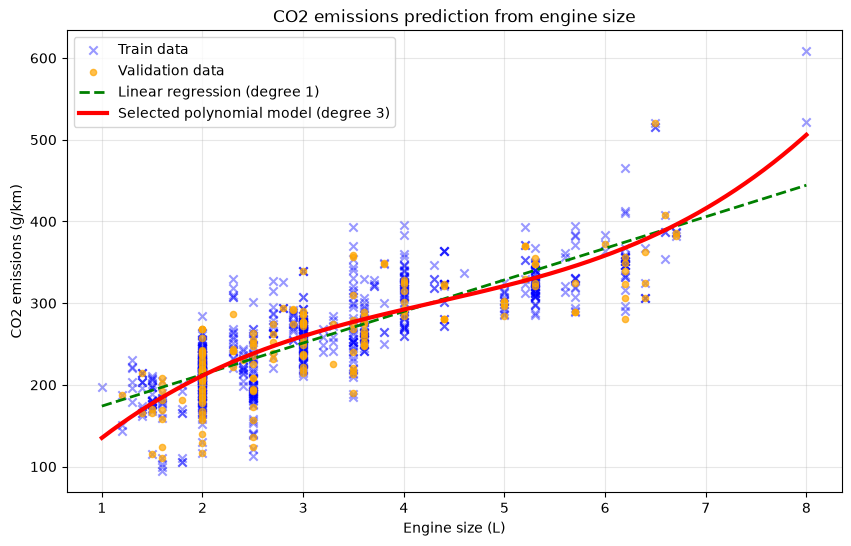

[19.069645187882713, 140.038522367984, -25.978944651393387, 2.0103505046552606]

In [4]:
def fit_best_polynomial(X, y, feature_names, title, max_degree=4, tolerance=0.005):
    """
    Split data into train/validation sets, choose the polynomial degree with 5-fold cross-validation
    (the simplest degree whose R^2 is within `tolerance` of the best one), fit and validate the model.
    """
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)
    X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

    kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    cv_scores = {}
    for degree in range(1, max_degree + 1):
        candidate = make_pipeline(PolynomialFeatures(degree=degree, include_bias=False), LinearRegression())
        cv_scores[degree] = cross_val_score(candidate, X_train, y_train, cv=kfold, scoring='r2').mean()
    best_score = max(cv_scores.values())
    best_degree = min(d for d, s in cv_scores.items() if s >= best_score - tolerance)

    model = make_pipeline(PolynomialFeatures(degree=best_degree, include_bias=False), LinearRegression())
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)

    print(f'===== {title} =====')
    print('5-fold cross-validation R^2 on the train split:')
    for degree, score in cv_scores.items():
        mark = '   <-- selected' if degree == best_degree else ''
        print(f'  degree {degree}: R^2 = {score:.4f}{mark}')
    print(f'Validation ({len(y_val)} samples): R^2 = {r2_score(y_val, y_pred):.4f}, '
          f'RMSE = {np.sqrt(mean_squared_error(y_val, y_pred)):.4f}, '
          f'MAE = {mean_absolute_error(y_val, y_pred):.4f}')

    poly = model.named_steps['polynomialfeatures']
    regression = model.named_steps['linearregression']
    term_names = ['intercept'] + list(poly.get_feature_names_out(feature_names))
    theta = [float(regression.intercept_)] + [float(c) for c in regression.coef_]
    print('Model parameters (theta):')
    for name, value in zip(term_names, theta):
        print(f'  {name:>35}: {value: .6g}')
    print()
    return {'model': model, 'degree': best_degree, 'theta': theta,
            'X_train': X_train, 'X_val': X_val, 'y_train': y_train, 'y_val': y_val}


def plot_1d_regression(result, x_label, y_label, title):
    """Plot train/validation points, a plain linear fit and the selected polynomial model."""
    model = result['model']
    degree = result['degree']
    linear = make_pipeline(PolynomialFeatures(degree=1, include_bias=False), LinearRegression())
    linear.fit(result['X_train'], result['y_train'])

    all_x = np.vstack([result['X_train'], result['X_val']])
    x_line = np.linspace(all_x.min(), all_x.max(), 300).reshape(-1, 1)

    plt.figure(figsize=(10, 6))
    plt.scatter(result['X_train'], result['y_train'], c='blue', marker='x', alpha=0.4, label='Train data')
    plt.scatter(result['X_val'], result['y_val'], c='orange', marker='o', s=20, alpha=0.7, label='Validation data')
    plt.plot(x_line, linear.predict(x_line), 'g--', lw=2, label='Linear regression (degree 1)')
    plt.plot(x_line, model.predict(x_line), 'r-', lw=3, label=f'Selected polynomial model (degree {degree})')
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


def CO2_emissions(data):
    """
    Build a model that would predict CO2 emissions from the size of the engine of car. Visualize model on a plot.

    Args:
        data: CO2 emissions data.

    Returns:
        list: The list of model theta parameters.
    """
    df = data[['Engine_Size', 'CO2_Emissions']].dropna()
    result = fit_best_polynomial(df[['Engine_Size']], df['CO2_Emissions'], ['Engine_Size'],
                                 title='CO2 emissions ~ engine size')
    plot_1d_regression(result, 'Engine size (L)', 'CO2 emissions (g/km)',
                       'CO2 emissions prediction from engine size')
    return result['theta']

data = extract_texts_from_file('resources/CO2_emission.csv')
CO2_emissions(data)

## Ice Cream Sales

Process file `ice_cream_selling_data.csv`. Build a model, that would predict ice cream sales based on the temperature. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

===== Ice cream sales ~ temperature =====
5-fold cross-validation R^2 on the train split:
  degree 1: R^2 = -0.1140
  degree 2: R^2 = 0.9097   <-- selected
  degree 3: R^2 = 0.8842
  degree 4: R^2 = 0.9107
Validation (10 samples): R^2 = 0.8431, RMSE = 3.8573, MAE = 3.2300
Model parameters (theta):
                            intercept:  2.76831
                          Temperature: -0.706419
                        Temperature^2:  1.87145



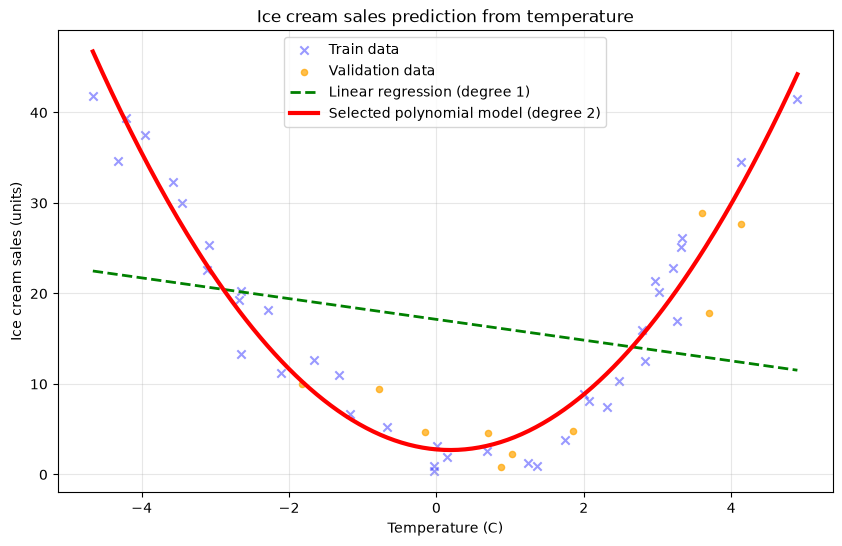

[2.768305829573862, -0.7064192581346761, 1.8714512493550588]

In [5]:
def ice_cream_selling(data):
    """
    Build a model, that would predict ice cream sales based on the temperature. Visualize model on a plot.

    Args:
        data: ice cream sales data.

    Returns:
        list: The list of model theta parameters.
    """
    # columns are taken by position: the temperature header contains a degree sign
    temperature_col, sales_col = data.columns[0], data.columns[1]
    df = data[[temperature_col, sales_col]].dropna()
    result = fit_best_polynomial(df[[temperature_col]], df[sales_col], ['Temperature'],
                                 title='Ice cream sales ~ temperature')
    plot_1d_regression(result, 'Temperature (C)', 'Ice cream sales (units)',
                       'Ice cream sales prediction from temperature')
    return result['theta']

data = extract_texts_from_file('resources/ice_cream_selling_data.csv')
ice_cream_selling(data)

## Electric Power Consumption

Process file `powerconsumption.csv`. Build a model, that would predict electricity consumption from the weather: temperature, humidity and wind speed. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

10-minute records: 52416, hourly records used for the model: 8736
Correlation with total consumption:
Temperature    0.492
Humidity      -0.302
WindSpeed      0.224

===== Total power consumption ~ temperature + humidity + wind speed =====
5-fold cross-validation R^2 on the train split:
  degree 1: R^2 = 0.2510
  degree 2: R^2 = 0.2915
  degree 3: R^2 = 0.3049   <-- selected
Validation (1748 samples): R^2 = 0.2891, RMSE = 14265.6878, MAE = 11362.5957
Model parameters (theta):
                            intercept:  181964
                          Temperature:  1378.34
                             Humidity: -5293.97
                            WindSpeed:  13.3142
                        Temperature^2: -261.531
                 Temperature Humidity:  58.8129
                Temperature WindSpeed: -391.978
                           Humidity^2:  72.0044
                   Humidity WindSpeed:  63.8373
                          WindSpeed^2:  154.3
                        Temperature^3:  4.

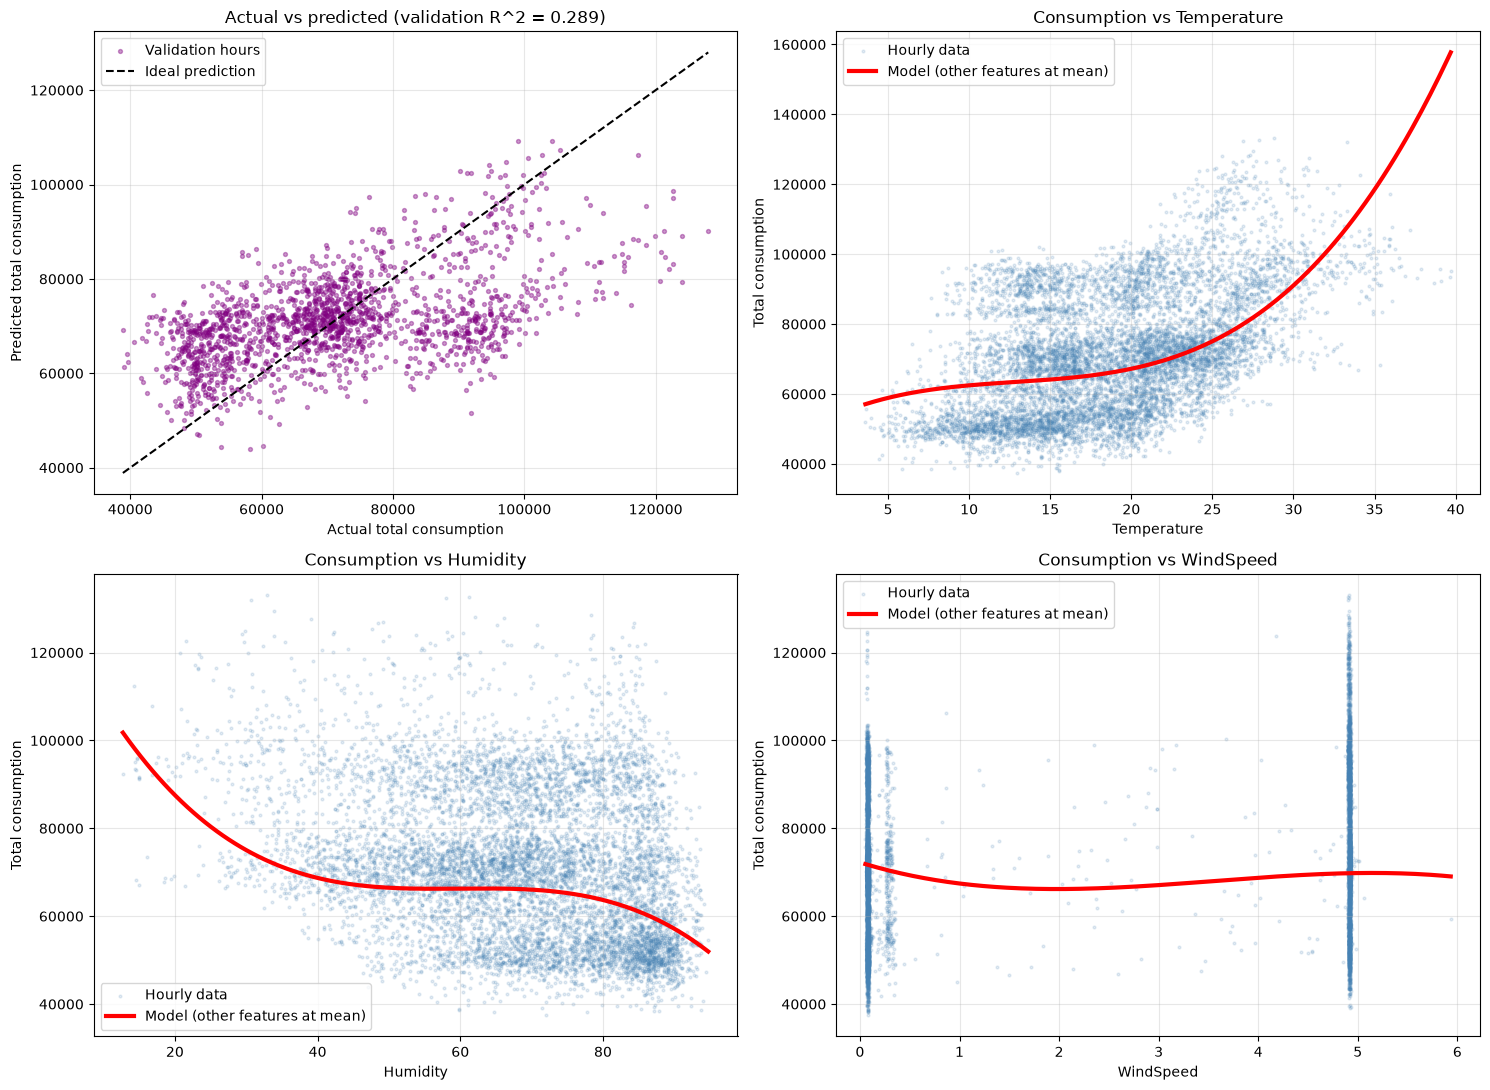

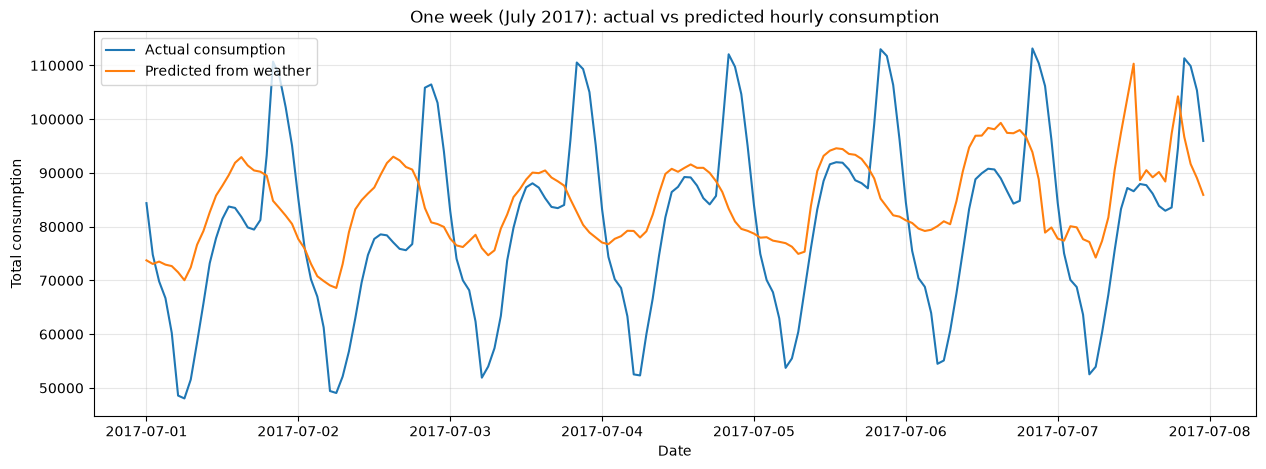

[181964.30205108278,
 1378.3427261724064,
 -5293.972190143576,
 13.314154587682305,
 -261.5312723842529,
 58.812908545468936,
 -391.9784953771668,
 72.00440922089383,
 63.83730543273191,
 154.29982265076612,
 4.46663607704884,
 1.168187137680206,
 4.744310855471538,
 -0.4642171770191336,
 -2.187751701551355,
 92.07018597494687,
 -0.3459204279687021,
 -0.6209944696566649,
 8.395509668977434,
 -230.1542633562661]

In [6]:
def power_consumption(data):
    """
    Build a model, that would predict electricity consumption from the weather: temperature, humidity and wind speed. 
    Visualize model on a plot.

    Args:
        data: power consumption data.

    Returns:
        list: The list of model theta parameters.
    """
    features = ['Temperature', 'Humidity', 'WindSpeed']
    df = data.copy()
    zone_columns = [c for c in df.columns if c.startswith('PowerConsumption')]
    df['TotalConsumption'] = df[zone_columns].sum(axis=1)
    df['Datetime'] = pd.to_datetime(df['Datetime'], format='%m/%d/%Y %H:%M', errors='coerce')

    # hourly averages remove 10-minute noise and keep the weather -> consumption relation
    hourly = (df.dropna(subset=['Datetime']).set_index('Datetime')[features + ['TotalConsumption']]
              .resample('h').mean().dropna())
    print(f'10-minute records: {len(df)}, hourly records used for the model: {len(hourly)}')
    print('Correlation with total consumption:')
    print(hourly.corr()['TotalConsumption'].drop('TotalConsumption').round(3).to_string())
    print()

    result = fit_best_polynomial(hourly[features], hourly['TotalConsumption'], features,
                                 title='Total power consumption ~ temperature + humidity + wind speed',
                                 max_degree=3)
    model = result['model']
    y_val = result['y_val']
    y_val_pred = model.predict(result['X_val'])

    fig, axes = plt.subplots(2, 2, figsize=(15, 11))
    ax = axes[0, 0]
    ax.scatter(y_val, y_val_pred, s=8, alpha=0.4, c='purple', label='Validation hours')
    limits = [min(y_val.min(), y_val_pred.min()), max(y_val.max(), y_val_pred.max())]
    ax.plot(limits, limits, 'k--', lw=1.5, label='Ideal prediction')
    ax.set_xlabel('Actual total consumption')
    ax.set_ylabel('Predicted total consumption')
    ax.set_title(f'Actual vs predicted (validation R^2 = {r2_score(y_val, y_val_pred):.3f})')
    ax.legend()
    ax.grid(alpha=0.3)

    # effect of each weather feature while the other two are fixed at their mean values
    means = hourly[features].mean().values
    for ax, (i, feature) in zip([axes[0, 1], axes[1, 0], axes[1, 1]], enumerate(features)):
        grid = np.tile(means, (200, 1))
        grid[:, i] = np.linspace(hourly[feature].min(), hourly[feature].max(), 200)
        ax.scatter(hourly[feature], hourly['TotalConsumption'], s=4, alpha=0.15, c='steelblue', label='Hourly data')
        ax.plot(grid[:, i], model.predict(grid), 'r-', lw=3, label='Model (other features at mean)')
        ax.set_xlabel(feature)
        ax.set_ylabel('Total consumption')
        ax.set_title(f'Consumption vs {feature}')
        ax.legend()
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    week = hourly.loc['2017-07-01':'2017-07-07']
    if not week.empty:
        plt.figure(figsize=(15, 5))
        plt.plot(week.index, week['TotalConsumption'], label='Actual consumption')
        plt.plot(week.index, model.predict(week[features].values), label='Predicted from weather')
        plt.xlabel('Date')
        plt.ylabel('Total consumption')
        plt.title('One week (July 2017): actual vs predicted hourly consumption')
        plt.legend()
        plt.grid(alpha=0.3)
        plt.show()

    return result['theta']

data = extract_texts_from_file('resources/powerconsumption.csv')
power_consumption(data)

## Heart Conditions Predictions

Process file `heart.csv`. It has the following data:

- age - Age of the patient
- sex - Sex of the patient
- cp - Chest pain type ~ 0 = Typical Angina, 1 = Atypical Angina, 2 = Non-anginal Pain, 3 = Asymptomatic
- trtbps - Resting blood pressure (in mm Hg)
- chol - Cholestoral in mg/dl fetched via BMI sensor
- fbs - (fasting blood sugar > 120 mg/dl) ~ 1 = True, 0 = False
- restecg - Resting electrocardiographic results ~ 0 = Normal, 1 = ST-T wave normality, 2 = Left ventricular hypertrophy
- thalachh - Maximum heart rate achieved
- oldpeak - Previous peak
- slp - Slope
- caa - Number of major vessels
- thall - Thalium Stress Test result ~ (0,3)
- exng - Exercise induced angina ~ 1 = Yes, 0 = No
- output - Target variable - risk of heart attack - 1 is high chance of heart attack and 0 is low chance.

Use classification model (choose model best fitting model yourself). Choose parameters that would best fit for making a prediction on. Visualize model on a plot.

Do not forget to split data into train data and validation data. Validate your model.

Train samples: 242, validation samples: 61

Absolute correlation of features with the target (train split):
cp          0.475
exng        0.451
oldpeak     0.445
thalachh    0.421
slp         0.395
thall       0.381
caa         0.352
sex         0.249
age         0.216
restecg     0.141
chol        0.139
trtbps      0.137
fbs         0.037

Cross-validated accuracy by number of top features:
  top  2 features: 0.7351
  top  3 features: 0.8134
  top  4 features: 0.8011
  top  5 features: 0.8093
  top  6 features: 0.8218
  top  7 features: 0.8468   <-- selected
  top  8 features: 0.8428
  top  9 features: 0.8386
  top 10 features: 0.8345
  top 11 features: 0.8303
  top 12 features: 0.8136
  top 13 features: 0.8136
Selected features: ['cp', 'exng', 'oldpeak', 'thalachh', 'slp', 'thall', 'caa']

Cross-validated accuracy by model:
  LogisticRegression  : 0.8468   <-- selected
  RidgeClassifier     : 0.8343
  SGDClassifier       : 0.8013

===== Validation of LogisticRegression =====
Accuracy

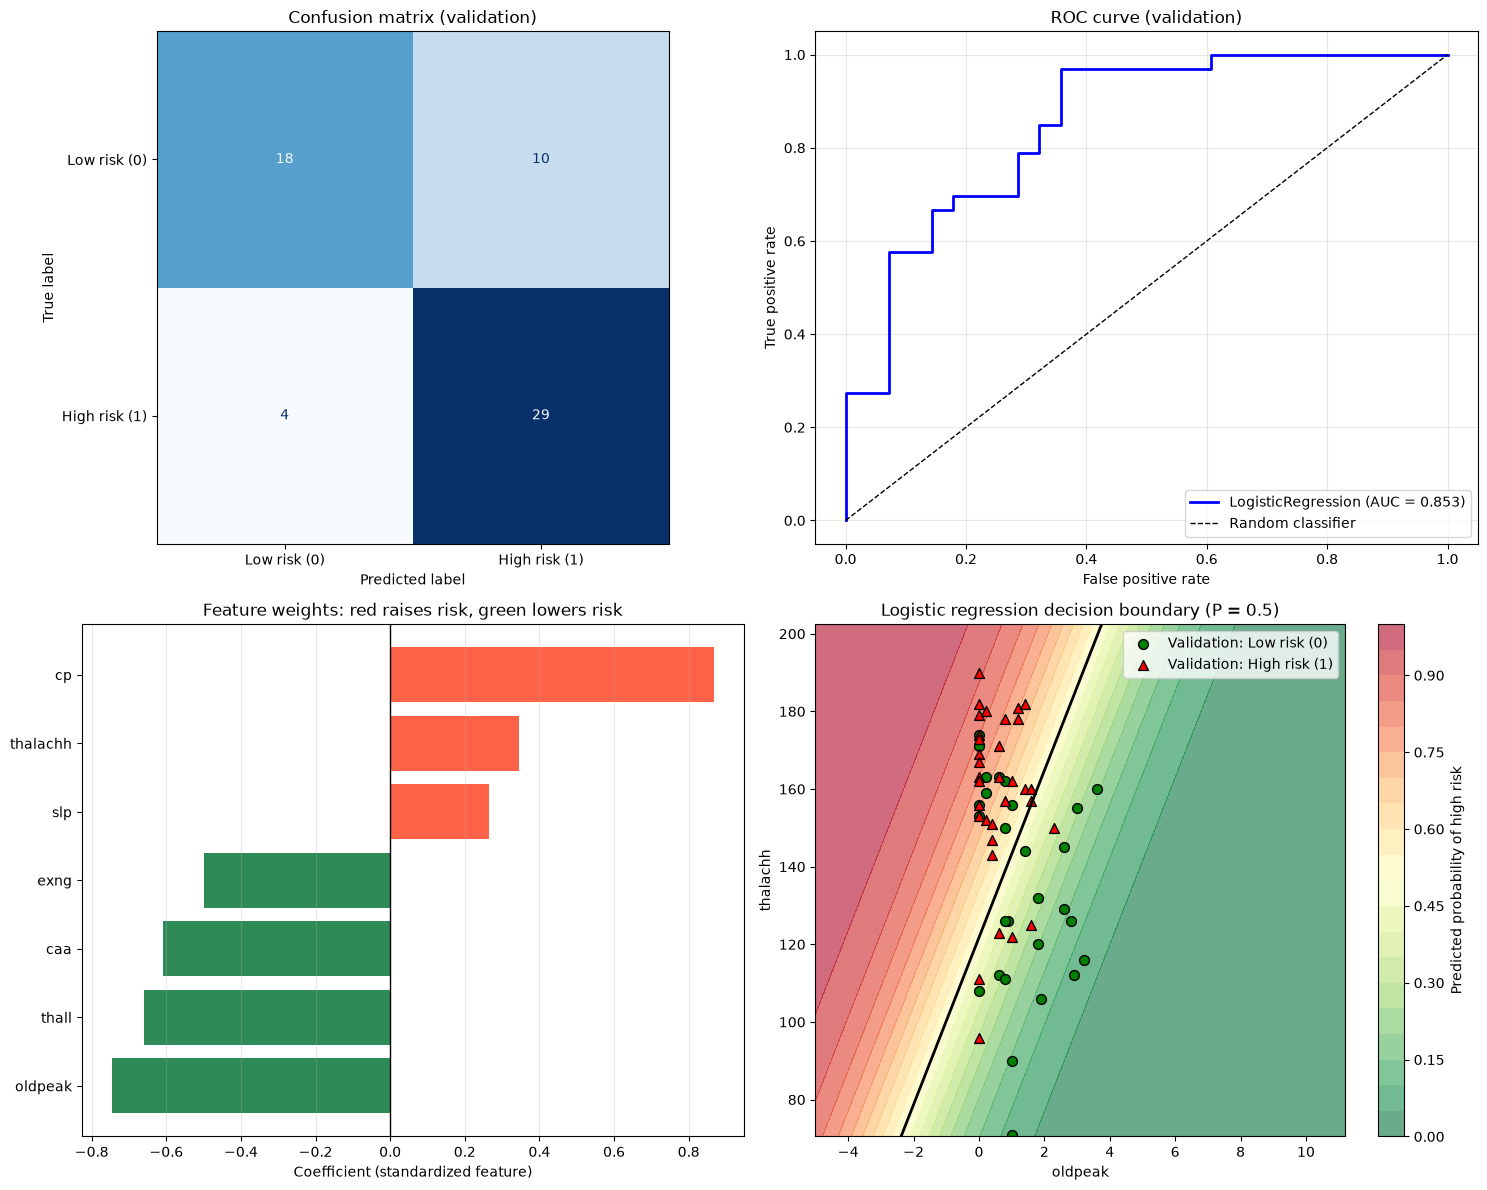

[0.10235617592018793,
 0.8672824618699398,
 -0.49825798780570113,
 -0.7458768214710062,
 0.34485755374237687,
 0.26390276925493455,
 -0.6598684668383461,
 -0.6073842309415879]

In [7]:
def heart_classification(data):
    """
    Build a model, that would classify risk category for heart attack. 
    Visualize model on a plot.

    Args:
        data: heart medical data.

    Returns:
        list: The list of model theta parameters.
    """
    target = 'output'
    df = data.dropna()
    X = df.drop(columns=[target])
    y = df[target]
    X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
    print(f'Train samples: {len(X_train)}, validation samples: {len(X_val)}')
    print()

    # 1. rank features on the train split only (absolute Pearson correlation with the target)
    correlations = X_train.corrwith(y_train).abs().sort_values(ascending=False)
    print('Absolute correlation of features with the target (train split):')
    print(correlations.round(3).to_string())
    print()

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

    def cv_accuracy(estimator, columns):
        pipeline = make_pipeline(StandardScaler(), estimator)
        return cross_val_score(pipeline, X_train[columns], y_train, cv=skf, scoring='accuracy').mean()

    # 2. choose how many of the top-ranked features to use
    k_scores = {k: cv_accuracy(LogisticRegression(max_iter=1000), list(correlations.index[:k]))
                for k in range(2, len(correlations) + 1)}
    best_k_score = max(k_scores.values())
    best_k = min(k for k, s in k_scores.items() if s >= best_k_score - 0.01)
    selected = list(correlations.index[:best_k])
    print('Cross-validated accuracy by number of top features:')
    for k, score in k_scores.items():
        mark = '   <-- selected' if k == best_k else ''
        print(f'  top {k:2d} features: {score:.4f}{mark}')
    print(f'Selected features: {selected}')
    print()

    # 3. compare classification models on the selected features
    candidates = {
        'LogisticRegression': LogisticRegression(max_iter=1000),
        'RidgeClassifier': RidgeClassifier(),
        'SGDClassifier': SGDClassifier(max_iter=2000, tol=1e-3, random_state=RANDOM_STATE),
    }
    model_scores = {name: cv_accuracy(estimator, selected) for name, estimator in candidates.items()}
    best_name = max(model_scores, key=model_scores.get)
    print('Cross-validated accuracy by model:')
    for name, score in model_scores.items():
        mark = '   <-- selected' if name == best_name else ''
        print(f'  {name:<20}: {score:.4f}{mark}')
    print()

    # 4. fit on the train split and validate on the held-out split
    pipeline = make_pipeline(StandardScaler(), candidates[best_name])
    pipeline.fit(X_train[selected], y_train)
    y_pred = pipeline.predict(X_val[selected])
    scores = pipeline.decision_function(X_val[selected])
    print(f'===== Validation of {best_name} =====')
    print(f'Accuracy: {accuracy_score(y_val, y_pred):.4f}')
    print(f'F1 score: {f1_score(y_val, y_pred):.4f}')
    print(f'ROC AUC : {roc_auc_score(y_val, scores):.4f}')
    class_names = ['Low risk (0)', 'High risk (1)']
    print(classification_report(y_val, y_pred, target_names=class_names))

    classifier = pipeline[-1]
    coefficients = np.ravel(classifier.coef_)
    theta = [float(np.ravel(classifier.intercept_)[0])] + [float(c) for c in coefficients]
    print('Model parameters (theta, standardized features):')
    for name, value in zip(['intercept'] + selected, theta):
        print(f'  {name:>10}: {value: .4f}')

    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    ConfusionMatrixDisplay.from_predictions(y_val, y_pred, display_labels=class_names,
                                            cmap='Blues', colorbar=False, ax=axes[0, 0])
    axes[0, 0].set_title('Confusion matrix (validation)')

    fpr, tpr, _ = roc_curve(y_val, scores)
    axes[0, 1].plot(fpr, tpr, 'b-', lw=2, label=f'{best_name} (AUC = {roc_auc_score(y_val, scores):.3f})')
    axes[0, 1].plot([0, 1], [0, 1], 'k--', lw=1, label='Random classifier')
    axes[0, 1].set_xlabel('False positive rate')
    axes[0, 1].set_ylabel('True positive rate')
    axes[0, 1].set_title('ROC curve (validation)')
    axes[0, 1].legend()
    axes[0, 1].grid(alpha=0.3)

    order = np.argsort(coefficients)
    colors = ['tomato' if c > 0 else 'seagreen' for c in coefficients[order]]
    axes[1, 0].barh(np.array(selected)[order], coefficients[order], color=colors)
    axes[1, 0].axvline(0, color='black', lw=1)
    axes[1, 0].set_xlabel('Coefficient (standardized feature)')
    axes[1, 0].set_title('Feature weights: red raises risk, green lowers risk')
    axes[1, 0].grid(alpha=0.3, axis='x')

    # decision boundary of a logistic regression on the two most informative continuous features
    continuous = [c for c in correlations.index if c in ['age', 'trtbps', 'chol', 'thalachh', 'oldpeak']][:2]
    boundary_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    boundary_model.fit(X_train[continuous], y_train)
    x_min, x_max = X[continuous[0]].min() - 5, X[continuous[0]].max() + 5
    y_min, y_max = X[continuous[1]].min() - 0.5, X[continuous[1]].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    grid = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=continuous)
    probabilities = boundary_model.predict_proba(grid)[:, 1].reshape(xx.shape)
    ax = axes[1, 1]
    contour = ax.contourf(xx, yy, probabilities, levels=20, cmap='RdYlGn_r', alpha=0.6)
    ax.contour(xx, yy, probabilities, levels=[0.5], colors='black', linewidths=2)
    for label, marker, color in [(0, 'o', 'green'), (1, '^', 'red')]:
        mask = y_val == label
        ax.scatter(X_val.loc[mask, continuous[0]], X_val.loc[mask, continuous[1]], marker=marker,
                   c=color, edgecolors='black', s=50, label=f'Validation: {class_names[label]}')
    fig.colorbar(contour, ax=ax, label='Predicted probability of high risk')
    ax.set_xlabel(continuous[0])
    ax.set_ylabel(continuous[1])
    ax.set_title('Logistic regression decision boundary (P = 0.5)')
    ax.legend(loc='upper right')
    plt.tight_layout()
    plt.show()

    return theta

data = extract_texts_from_file('resources/heart.csv')
heart_classification(data)

## Additional (extra credit)

There are more files in the resources folder. Take a look at the. Visualize data in these files. Choose ML algorithm for building a model and making predictions for new data. Visualize the model.

===== China GDP: sigmoid regression =====
beta_1 = 716.3541, beta_2 = 0.997201
Validation R^2 = 0.9788, MAE = 320.2 billion USD
Predictions for new years:
  2015: 9.46 trillion USD
  2016: 9.71 trillion USD
  2017: 9.90 trillion USD
  2018: 10.03 trillion USD
  2019: 10.12 trillion USD
  2020: 10.19 trillion USD



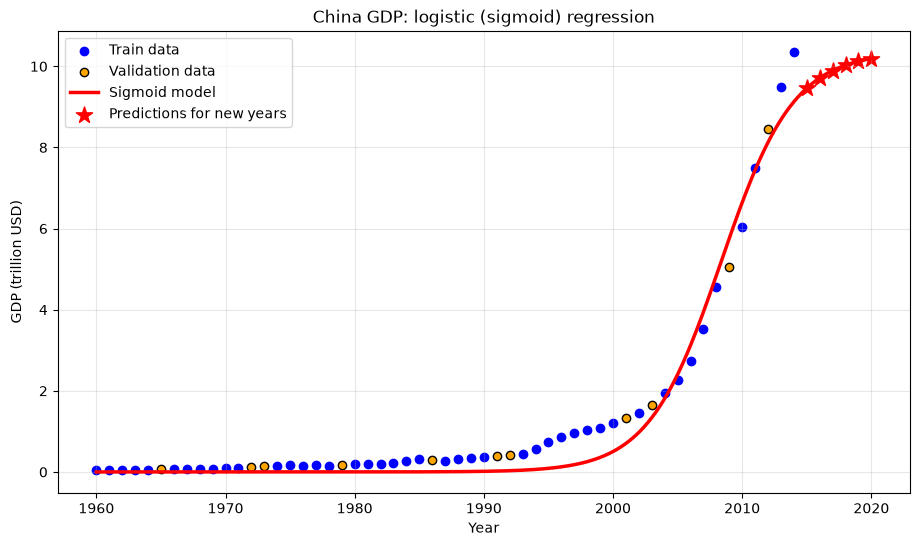

[716.3540703245764, 0.997200833952401]

In [8]:
def sigmoid(x, beta_1, beta_2):
    return 1.0 / (1.0 + np.exp(-beta_1 * (x - beta_2)))


def china_gdp_model(data):
    """Non-linear (logistic / sigmoid) regression of China's GDP over the years."""
    years = data['Year'].values.astype(float)
    gdp = data['Value'].values.astype(float)
    year_max, gdp_max = years.max(), gdp.max()
    x_norm, y_norm = years / year_max, gdp / gdp_max

    x_train, x_val, y_train, y_val = train_test_split(x_norm, y_norm, test_size=0.2, random_state=RANDOM_STATE)
    (beta_1, beta_2), _ = curve_fit(sigmoid, x_train, y_train, p0=[100.0, 0.995], maxfev=20000)
    y_val_pred = sigmoid(x_val, beta_1, beta_2)

    print('===== China GDP: sigmoid regression =====')
    print(f'beta_1 = {beta_1:.4f}, beta_2 = {beta_2:.6f}')
    print(f'Validation R^2 = {r2_score(y_val, y_val_pred):.4f}, '
          f'MAE = {mean_absolute_error(y_val, y_val_pred) * gdp_max / 1e9:.1f} billion USD')

    future_years = np.arange(year_max + 1, year_max + 7)
    future_gdp = sigmoid(future_years / year_max, beta_1, beta_2) * gdp_max
    print('Predictions for new years:')
    for year, value in zip(future_years, future_gdp):
        print(f'  {int(year)}: {value / 1e12:.2f} trillion USD')
    print()

    curve_years = np.linspace(years.min(), future_years.max(), 400)
    plt.figure(figsize=(11, 6))
    plt.scatter(x_train * year_max, y_train * gdp_max / 1e12, c='blue', label='Train data')
    plt.scatter(x_val * year_max, y_val * gdp_max / 1e12, c='orange', edgecolors='black', label='Validation data')
    plt.plot(curve_years, sigmoid(curve_years / year_max, beta_1, beta_2) * gdp_max / 1e12, 'r-', lw=2.5,
             label='Sigmoid model')
    plt.scatter(future_years, future_gdp / 1e12, c='red', marker='*', s=150, label='Predictions for new years')
    plt.xlabel('Year')
    plt.ylabel('GDP (trillion USD)')
    plt.title('China GDP: logistic (sigmoid) regression')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()
    return [float(beta_1), float(beta_2)]


def drug_classification(data):
    """Decision tree that chooses a drug for a patient (drug.csv)."""
    df = data.dropna().copy()
    encoders = {'sex': {'F': 0, 'M': 1},
                'bp': {'LOW': 0, 'NORMAL': 1, 'HIGH': 2},
                'cholesterol': {'NORMAL': 0, 'HIGH': 1}}
    for column, mapping in encoders.items():
        df[column] = df[column].astype(str).str.upper().map(mapping)
    features = ['age', 'sex', 'bp', 'cholesterol', 'Na_to_K']
    X, y = df[features], df['drug']
    X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    depth_scores = {d: cross_val_score(DecisionTreeClassifier(criterion='entropy', max_depth=d,
                                                              random_state=RANDOM_STATE),
                                       X_train, y_train, cv=skf, scoring='accuracy').mean()
                    for d in range(1, 9)}
    best_depth_score = max(depth_scores.values())
    best_depth = min(d for d, s in depth_scores.items() if s >= best_depth_score - 0.005)

    tree = DecisionTreeClassifier(criterion='entropy', max_depth=best_depth, random_state=RANDOM_STATE)
    tree.fit(X_train, y_train)
    y_pred = tree.predict(X_val)

    print('===== Drug classification: decision tree =====')
    print('Cross-validated accuracy by tree depth:')
    for depth, score in depth_scores.items():
        mark = '   <-- selected' if depth == best_depth else ''
        print(f'  max_depth {depth}: {score:.4f}{mark}')
    print(f'Validation accuracy: {accuracy_score(y_val, y_pred):.4f}')
    print(classification_report(y_val, y_pred))

    new_patients = pd.DataFrame([[25, 0, 2, 1, 28.0], [60, 1, 0, 1, 10.5], [45, 1, 1, 0, 8.2]], columns=features)
    predictions = tree.predict(new_patients)
    print('Predictions for new patients (sex: F=0/M=1, bp: LOW=0/NORMAL=1/HIGH=2, cholesterol: NORMAL=0/HIGH=1):')
    print(new_patients.assign(predicted_drug=predictions).to_string(index=False))

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    for drug in sorted(df['drug'].unique()):
        subset = df[df['drug'] == drug]
        axes[0].scatter(subset['Na_to_K'], subset['age'], s=40, alpha=0.8, label=drug)
    axes[0].axvline(15, color='gray', ls='--', lw=1)
    axes[0].set_xlabel('Na_to_K ratio')
    axes[0].set_ylabel('Age')
    axes[0].set_title('Drug data: Na_to_K vs age')
    axes[0].legend()
    axes[0].grid(alpha=0.3)
    ConfusionMatrixDisplay.from_predictions(y_val, y_pred, cmap='Blues', colorbar=False, ax=axes[1])
    axes[1].set_title('Decision tree: confusion matrix (validation)')
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(18, 8))
    plot_tree(tree, feature_names=features, class_names=list(tree.classes_), filled=True, rounded=True, fontsize=10)
    plt.title(f'Decision tree for drug selection (max_depth = {best_depth})')
    plt.show()
    return {'max_depth': best_depth,
            'feature_importances': dict(zip(features, np.round(tree.feature_importances_, 4)))}


def additional(data):
    if data is None or data.empty:
        print('No data to analyse.')
        return None
    columns = set(data.columns)
    if {'Year', 'Value'} <= columns:
        return china_gdp_model(data)
    if {'Na_to_K', 'drug'} <= columns:
        return drug_classification(data)
    print(f'Unsupported dataset with columns: {sorted(columns)}')
    return None

data = extract_texts_from_file('resources/china_gdp.csv')
additional(data)

===== Drug classification: decision tree =====
Cross-validated accuracy by tree depth:
  max_depth 1: 0.7250
  max_depth 2: 0.8375
  max_depth 3: 0.9062
  max_depth 4: 1.0000   <-- selected
  max_depth 5: 1.0000
  max_depth 6: 1.0000
  max_depth 7: 1.0000
  max_depth 8: 1.0000
Validation accuracy: 0.9750
              precision    recall  f1-score   support

       drugA       0.83      1.00      0.91         5
       drugB       1.00      0.67      0.80         3
       drugC       1.00      1.00      1.00         3
       drugX       1.00      1.00      1.00        11
       drugY       1.00      1.00      1.00        18

    accuracy                           0.97        40
   macro avg       0.97      0.93      0.94        40
weighted avg       0.98      0.97      0.97        40

Predictions for new patients (sex: F=0/M=1, bp: LOW=0/NORMAL=1/HIGH=2, cholesterol: NORMAL=0/HIGH=1):
 age  sex  bp  cholesterol  Na_to_K predicted_drug
  25    0   2            1     28.0          drugY
 

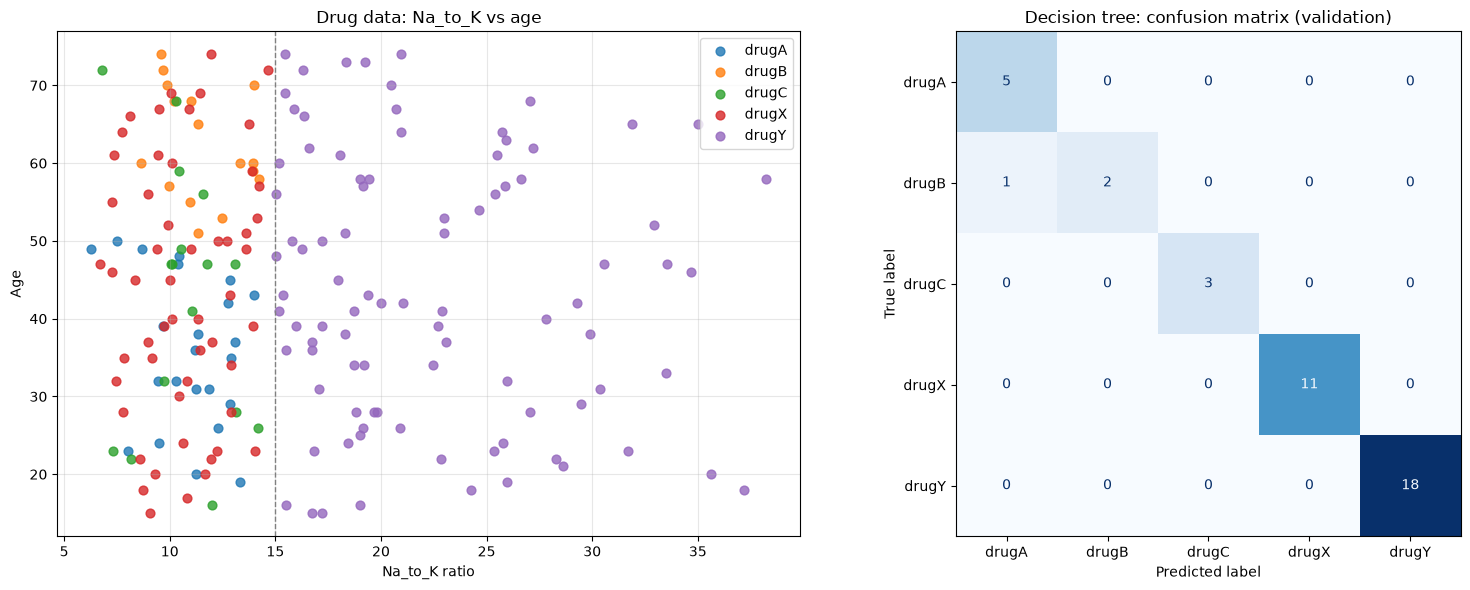

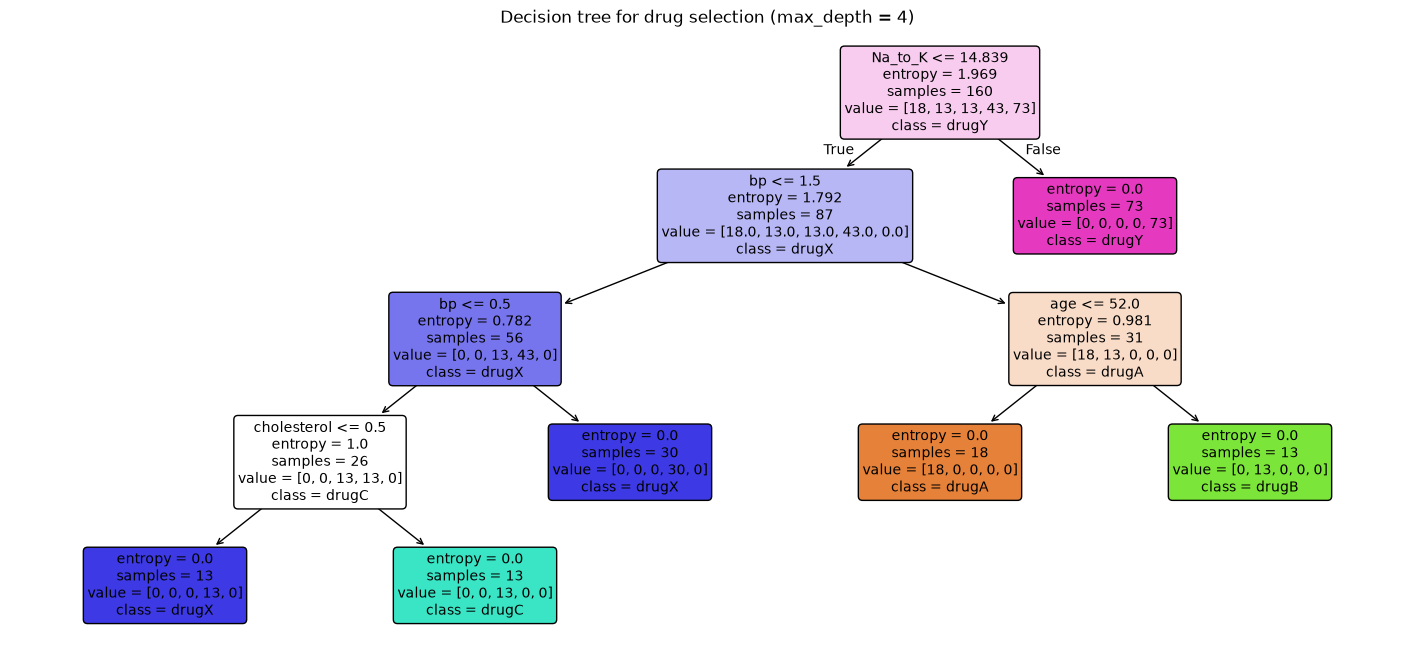

{'max_depth': 4,
 'feature_importances': {'age': np.float64(0.0965),
  'sex': np.float64(0.0),
  'bp': np.float64(0.3159),
  'cholesterol': np.float64(0.0825),
  'Na_to_K': np.float64(0.505)}}

In [9]:
data = extract_texts_from_file('resources/drug.csv')
additional(data)

## Machine learning analysis on texts

Predict text score (sentiment, holistic score, etc., any other target label) using machine learning algorithm you see best fit for the task. Choose kaggle dataset from available below. Display classification report (confusion matrix, accuracy, f1 score, etc.). 

- Learning Agency Lab - Automated Essay Scoring 2.0: predict holistic text score given full_text (student essays) https://www.kaggle.com/competitions/learning-agency-lab-automated-essay-scoring-2
- 100K Coursera's Course Reviews Dataset: predict the final rating (1 to 5) based on the text of the review https://www.kaggle.com/datasets/septa97/100k-courseras-course-reviews-dataset
- LLM - Detect AI Generated Text: predict the target label (0 being written by student and 1 being written by LLM) given the full text https://www.kaggle.com/competitions/llm-detect-ai-generated-text
- 42K+ Udemy Course Enrollment Information Dataset🔥: classify course categories using Title and Summary; compare text-only features against combined title-and-summary features https://www.kaggle.com/datasets/songseungwon/2020-udemy-courses-dataset
- TMDB 5000 Movie Dataset: movie classification based on description https://www.kaggle.com/datasets/tmdb/tmdb-movie-metadata?select=tmdb_5000_movies.csv



In [10]:
# pip install "kagglehub[pandas-datasets]"

# If loading dataset via kaggle package fails (some of these do right now when I try because of encoding issues), 
# donwload the dataset manually from webpage and place csv file(s) in the resources folder.
def load_dataset(url, csv_file):
    """
    Load the dataset from Kaggle using kagglehub.

    Args:
        url (str): The URL of the Kaggle dataset.
        csv_file (str): The name of the CSV file to load from the dataset.
    Returns:
        pd.DataFrame: The loaded dataset as a pandas DataFrame.
    """
    local_path = os.path.join('resources', csv_file)
    if os.path.exists(local_path):
        print(f'Loading local copy: {local_path}')
        return pd.read_csv(local_path)
    try:
        import kagglehub
        from kagglehub import KaggleDatasetAdapter
    except ImportError:
        print('kagglehub is not installed: pip install "kagglehub[pandas-datasets]"')
        return None
    attempts = [
        lambda: kagglehub.dataset_load(KaggleDatasetAdapter.PANDAS, url, csv_file),
        lambda: kagglehub.dataset_load(KaggleDatasetAdapter.PANDAS, url, csv_file,
                                       pandas_kwargs={'encoding': 'latin-1'}),
    ]
    last_error = None
    for attempt in attempts:
        try:
            return attempt()
        except Exception as error:
            last_error = error
    print(f'Could not load {csv_file} from {url}: {last_error}')
    print(f'Download it manually and place {csv_file} into the resources folder.')
    return None

def classify_text_ml(df):
    """
    Classify text data using a machine learning model.

    Args:
        df (pd.DataFrame): The input DataFrame containing text data.

    Returns:
        None
    """
    print('Classifying text data...')
    if df is None or df.empty:
        print('No data to classify.')
        return None

    lower = {c.lower(): c for c in df.columns}
    text_col = next((lower[c] for c in ('review', 'text', 'full_text', 'overview', 'description') if c in lower), None)
    label_col = next((lower[c] for c in ('label', 'rating', 'score', 'generated') if c in lower), None)
    if text_col is None or label_col is None:
        print(f'Could not find text/label columns in: {list(df.columns)}')
        return None

    data = df[[text_col, label_col]].dropna()
    data = data[data[text_col].astype(str).str.strip().str.len() > 0]
    texts = data[text_col].astype(str)
    labels = data[label_col].astype(int)
    print(f'Dataset size: {len(data)} texts')
    print('Label distribution:')
    print(labels.value_counts().sort_index().to_string())
    print()

    X_train, X_test, y_train, y_test = train_test_split(texts, labels, test_size=0.2, stratify=labels,
                                                        random_state=RANDOM_STATE)
    # stop words are kept on purpose: negations like 'not good' matter for the rating
    vectorizer = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=3, max_df=0.95,
                                 sublinear_tf=True, max_features=200000)
    X_train_vec = vectorizer.fit_transform(X_train)
    X_test_vec = vectorizer.transform(X_test)

    baseline = DummyClassifier(strategy='most_frequent').fit(X_train_vec, y_train)
    model = LogisticRegression(max_iter=1000, C=2.0, class_weight='balanced')
    model.fit(X_train_vec, y_train)

    for name, classifier in [('Baseline (most frequent class)', baseline), ('TF-IDF + Logistic Regression', model)]:
        predictions = classifier.predict(X_test_vec)
        print(f'{name:<32} accuracy = {accuracy_score(y_test, predictions):.4f}, '
              f'macro F1 = {f1_score(y_test, predictions, average="macro"):.4f}, '
              f'weighted F1 = {f1_score(y_test, predictions, average="weighted"):.4f}')
    print()

    y_pred = model.predict(X_test_vec)
    print('Classification report (TF-IDF + Logistic Regression):')
    print(classification_report(y_test, y_pred, digits=3))

    feature_names = vectorizer.get_feature_names_out()
    print('Most indicative words/phrases per class:')
    for index, label in enumerate(model.classes_):
        top = np.argsort(model.coef_[index])[-10:][::-1]
        print(f'  {label}: {", ".join(feature_names[top])}')
    print()

    examples = ['This course was amazing, the instructor explained everything clearly!',
                'Boring lectures and outdated material, I would not recommend it.',
                'Good content, but the assignments were sometimes confusing.']
    print('Predictions for new reviews:')
    for text, prediction in zip(examples, model.predict(vectorizer.transform(examples))):
        print(f'  [{prediction}] {text}')

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    labels.value_counts().sort_index().plot(kind='bar', ax=axes[0], color='steelblue')
    axes[0].set_xlabel('Label')
    axes[0].set_ylabel('Number of texts')
    axes[0].set_title('Label distribution')
    axes[0].grid(alpha=0.3, axis='y')
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, normalize='true', values_format='.2f',
                                            cmap='Blues', ax=axes[1])
    axes[1].set_title('Normalized confusion matrix (test set)')
    plt.tight_layout()
    plt.show()
    return None

df = load_dataset('septa97/100k-courseras-course-reviews-dataset', 'reviews.csv')
classify_text_ml(df)

100%|██████████| 5.50M/5.50M [00:00<00:00, 6.12MB/s]


Could not load reviews.csv from septa97/100k-courseras-course-reviews-dataset: Error reading file: Error tokenizing data. C error: Buffer overflow caught - possible malformed input file.

Download it manually and place reviews.csv into the resources folder.
Classifying text data...
No data to classify.
